# Notebook 03 — Module C: Customer Segmentation & Value

**Dataset:** UCI Online Retail II (cleaned in notebook 00), only lines with a `Customer ID`.

**Part 1 — Segmentation:** group customers by **RFM** (Recency, Frequency, Monetary) with **K-Means**, and describe each
segment's **historical** value.

**Part 2 — Future value (optional extension, now possible):** because Online Retail II covers two years of real repeat
customers, we can build a genuine **future-spend target** with a time split: features from the first 18 months,
target = spend in the **following 6 months**. This is an honest, limited form of Customer Lifetime Value (CLV) prediction.

- **Recency (R):** days since the customer's last purchase (lower = more recent).
- **Frequency (F):** number of distinct (non-cancelled) invoices.
- **Monetary (M):** net spend in £ (purchases minus cancellations).

## Setup

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (calinski_harabasz_score, davies_bouldin_score, mean_absolute_error, mean_squared_error,
                             median_absolute_error, r2_score, silhouette_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from xgboost import XGBRegressor

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN_PATH = PROJECT_ROOT / "data" / "processed" / "online_retail_clean.csv.gz"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
PRED_DIR = PROJECT_ROOT / "outputs" / "predictions"
MODEL_DIR = PROJECT_ROOT / "models"
for folder in (FIG_DIR, TABLE_DIR, PRED_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titlesize": 13, "axes.labelsize": 11})
MAIN_COLOR = "#4C72B0"
ACCENT_COLOR = "#DD8452"

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"03_{name}.png", dpi=120, bbox_inches="tight")

retail = pd.read_csv(CLEAN_PATH, parse_dates=["InvoiceDate"], dtype={"Invoice": str, "StockCode": str})
customers_lines = retail.dropna(subset=["Customer ID"]).assign(**{"Customer ID": lambda d: d["Customer ID"].astype(int)})
print(f"Lines with a Customer ID: {len(customers_lines):,} of {len(retail):,}")

Lines with a Customer ID: 794,183 of 1,021,272


# Part 1 — RFM segmentation

## Step 1 — Build one row per customer

- **Snapshot date:** the day after the last invoice (**2011-12-10**). Recency is measured from this date.
- **Observation window:** 2009-12-01 to 2011-12-09 (two years).
- Frequency counts distinct non-cancelled invoices; Monetary is **net** of cancellations.
- Customers whose net spend is zero or negative (they cancelled everything) are excluded — they have no purchasing value to segment.

In [2]:
def build_rfm(lines, snapshot_date):
    """Customer-level RFM table from transaction lines (features use only lines before `snapshot_date`)."""
    lines = lines[lines["InvoiceDate"] < snapshot_date]
    purchases = lines[~lines["is_cancellation"]]
    rfm = purchases.groupby("Customer ID").agg(
        first_purchase=("InvoiceDate", "min"), last_purchase=("InvoiceDate", "max"), Frequency=("Invoice", "nunique"))
    rfm["Monetary"] = lines.groupby("Customer ID")["revenue"].sum().round(2)  # pennies; removes floating-point noise
    rfm["Recency"] = (snapshot_date - rfm["last_purchase"]).dt.days
    rfm["Tenure"] = (snapshot_date - rfm["first_purchase"]).dt.days
    rfm["avg_order_value"] = rfm["Monetary"] / rfm["Frequency"]
    return rfm[rfm["Monetary"] > 0]

SNAPSHOT_DATE = customers_lines["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
rfm = build_rfm(customers_lines, SNAPSHOT_DATE)
RFM_COLUMNS = ["Recency", "Frequency", "Monetary"]
print("Snapshot date:", SNAPSHOT_DATE.date(), "| customers:", len(rfm),
      "| excluded (net spend <= 0):", customers_lines["Customer ID"].nunique() - len(rfm))
rfm[RFM_COLUMNS + ["avg_order_value"]].describe().round(1)

Snapshot date: 2011-12-10 | customers: 5832 | excluded (net spend <= 0): 43


,Recency,Frequency,Monetary,avg_order_value
count,5832.0,5832.0,5832.0,5832.0
mean,199.4,6.3,2805.5,356.5
std,208.4,12.8,13847.9,474.1
min,0.0,1.0,2.9,1.4
25%,25.0,1.0,333.8,172.9
50%,95.0,3.0,843.7,272.2
75%,378.0,7.0,2179.9,403.5
max,738.0,373.0,578408.6,13206.5


**Interpretation:** 5,832 customers. The median customer placed 3 orders, spent about £840 and last bought about
3 months before the snapshot, but the means are far larger (e.g. mean spend ≈ £2,800, maximum ≈ £578,000): a few
wholesale customers spend enormously more than everyone else.

## Step 2 — Distributions and transformation

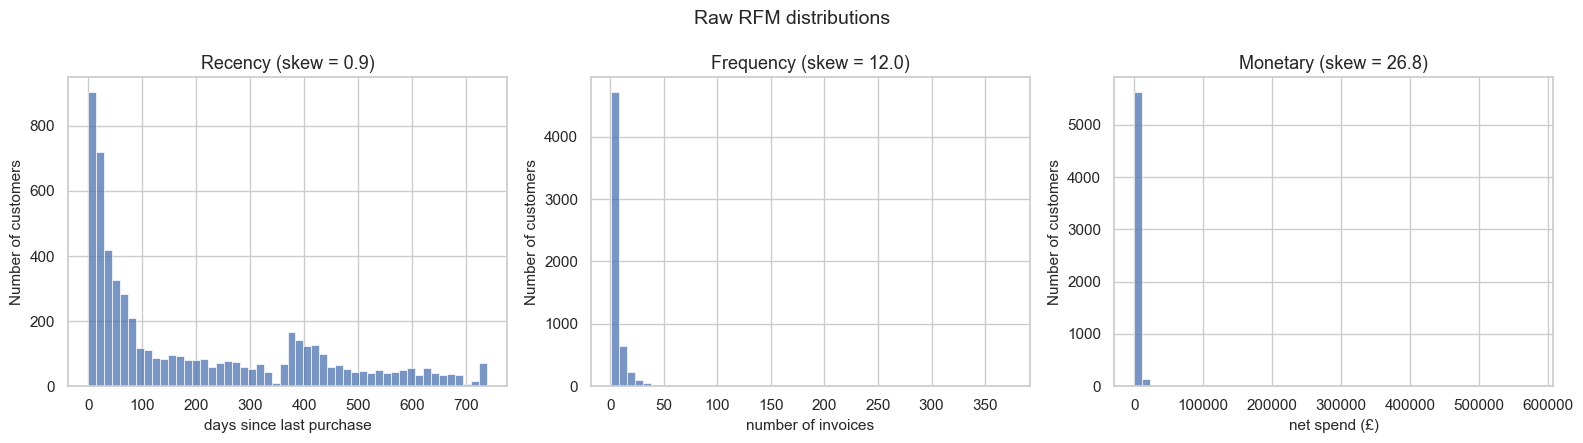

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, column, unit in zip(axes, RFM_COLUMNS, ["days since last purchase", "number of invoices", "net spend (£)"]):
    sns.histplot(rfm[column], bins=50, ax=ax, color=MAIN_COLOR)
    ax.set_title(f"{column} (skew = {rfm[column].skew():.1f})")
    ax.set_xlabel(unit)
    ax.set_ylabel("Number of customers")
fig.suptitle("Raw RFM distributions", fontsize=14)
save_fig("rfm_raw_distributions")
plt.show()

**Interpretation:** Frequency (skew ≈ 12) and Monetary (skew ≈ 27) are *extremely* skewed — on the raw scale almost all
customers are squeezed into the first bar. Recency is moderately skewed and has a second bump around one year
(customers who bought only in the first year).

**Decision (documented transformation):** apply `log1p` (= log(1 + x)) to **all three** features — all are ≥ 0, so the
transform is valid — then **standardise** them. Without this, K-Means would mostly separate a handful of wholesalers
from everyone else. Both steps are stored in one pipeline so new customers are transformed identically.

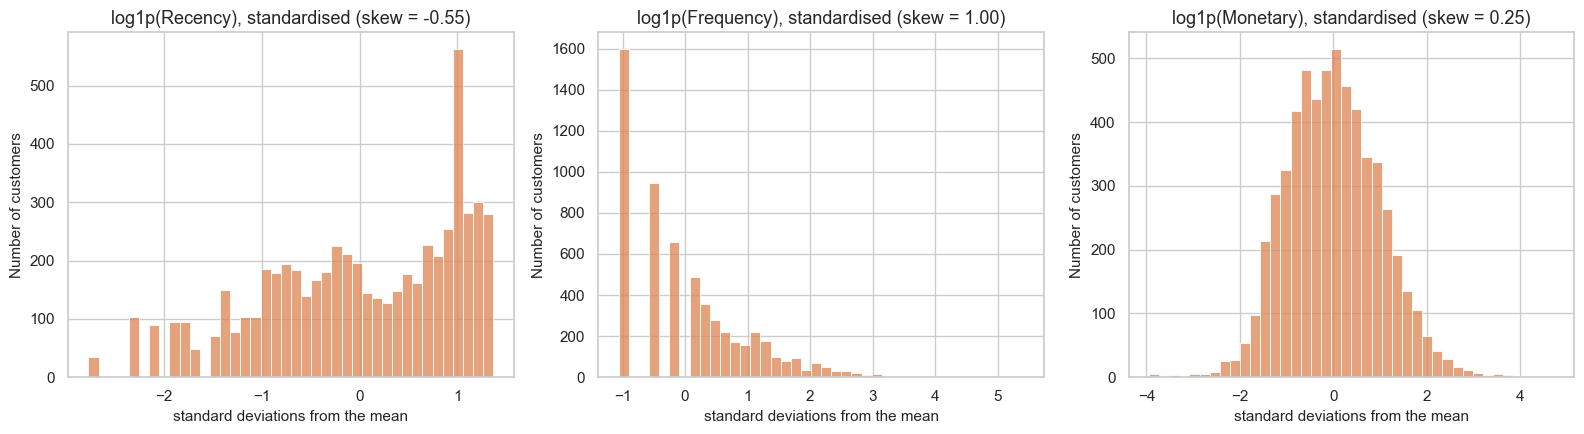

Invalid values after transform: False


In [4]:
scaler_pipeline = make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler())
rfm_scaled = pd.DataFrame(scaler_pipeline.fit_transform(rfm[RFM_COLUMNS]), columns=RFM_COLUMNS, index=rfm.index)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, column in zip(axes, RFM_COLUMNS):
    sns.histplot(rfm_scaled[column], bins=40, ax=ax, color=ACCENT_COLOR)
    ax.set_title(f"log1p({column}), standardised (skew = {rfm_scaled[column].skew():.2f})")
    ax.set_xlabel("standard deviations from the mean")
    ax.set_ylabel("Number of customers")
save_fig("rfm_transformed_distributions")
plt.show()
print("Invalid values after transform:", bool(rfm_scaled.isna().any().any() or np.isinf(rfm_scaled.values).any()))

**Interpretation:** after the log transform the three features are on comparable, much less skewed scales, with no
invalid values. Recency becomes left-skewed (many customers bought in the last few weeks), which is acceptable.

## Step 3 — Choose the number of clusters

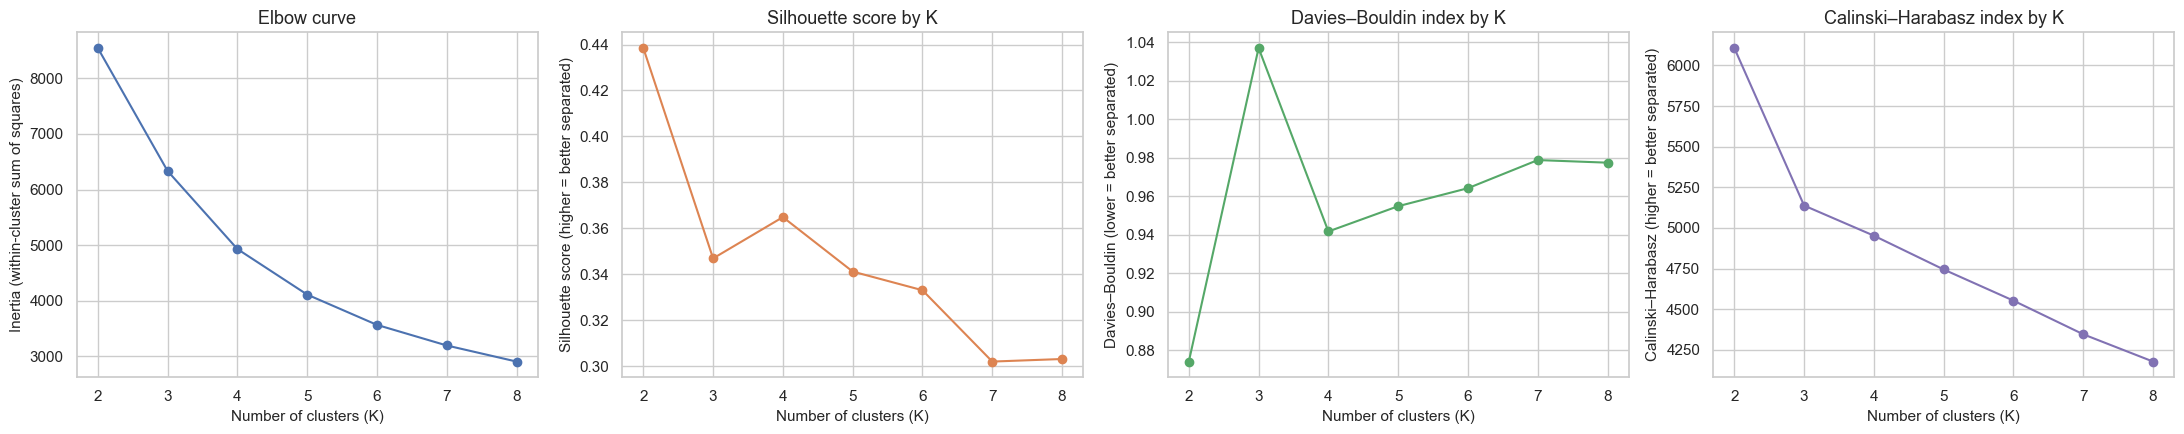

,inertia,silhouette,davies_bouldin,calinski_harabasz
K,,,,
2,8544.558,0.438,0.874,6107.628
3,6332.763,0.347,1.037,5137.614
4,4929.730,0.365,0.942,4952.069
5,4110.411,0.341,0.955,4743.943
6,3565.847,0.333,0.964,4551.951
7,3195.521,0.302,0.979,4344.814
8,2906.162,0.303,0.977,4176.926


In [5]:
k_rows = []
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(rfm_scaled)
    k_rows.append({"K": k, "inertia": kmeans.inertia_, "silhouette": silhouette_score(rfm_scaled, kmeans.labels_),
                   "davies_bouldin": davies_bouldin_score(rfm_scaled, kmeans.labels_),
                   "calinski_harabasz": calinski_harabasz_score(rfm_scaled, kmeans.labels_)})
k_evaluation = pd.DataFrame(k_rows).set_index("K")

fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
axes[0].plot(k_evaluation.index, k_evaluation["inertia"], marker="o", color=MAIN_COLOR)
axes[0].set_title("Elbow curve")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[1].plot(k_evaluation.index, k_evaluation["silhouette"], marker="o", color=ACCENT_COLOR)
axes[1].set_title("Silhouette score by K")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score (higher = better separated)")
axes[2].plot(k_evaluation.index, k_evaluation["davies_bouldin"], marker="o", color="#55A868")
axes[2].set_title("Davies–Bouldin index by K")
axes[2].set_xlabel("Number of clusters (K)")
axes[2].set_ylabel("Davies–Bouldin (lower = better separated)")
axes[3].plot(k_evaluation.index, k_evaluation["calinski_harabasz"], marker="o", color="#8172B3")
axes[3].set_title("Calinski–Harabasz index by K")
axes[3].set_xlabel("Number of clusters (K)")
axes[3].set_ylabel("Calinski–Harabasz (higher = better separated)")
save_fig("elbow_silhouette")
plt.show()
k_evaluation.round(3)

**Interpretation:** inertia drops steeply up to K = 4 and the gains shrink afterwards (an elbow around 4). K = 2 has the
highest silhouette (0.44) but only splits "active" from "inactive" customers. **K = 4 has the best silhouette among
K ≥ 3 (≈ 0.365)** — a local peak, higher than both K = 3 and K = 5.

**Additional cluster-quality metrics:** the **Davies–Bouldin** index (lower = better) agrees with the silhouette:
K = 2 is best (0.87), and among K ≥ 3, K = 4 is best (0.94 vs 1.04 for K = 3 and 0.96 for K = 5). The
**Calinski–Harabasz** index falls steadily as K grows (6,108 at K = 2 → 4,952 at K = 4), so it does not
identify a K beyond 2 on its own. Two of the three metrics therefore single out K = 4 as the best K ≥ 3.

**Decision:** choose **K = 4**.

## Step 4 — Train the final K-Means pipeline

In [6]:
N_CLUSTERS = 4
segmentation_pipeline = Pipeline([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
    ("kmeans", KMeans(n_clusters=N_CLUSTERS, n_init=20, random_state=RANDOM_STATE)),
])
rfm["cluster"] = segmentation_pipeline.fit_predict(rfm[RFM_COLUMNS])
final_silhouette = silhouette_score(segmentation_pipeline[:-1].transform(rfm[RFM_COLUMNS]), rfm["cluster"])
final_scaled = segmentation_pipeline[:-1].transform(rfm[RFM_COLUMNS])
print(f"K = {N_CLUSTERS}, silhouette = {final_silhouette:.3f}, "
      f"Davies–Bouldin = {davies_bouldin_score(final_scaled, rfm['cluster']):.3f}, "
      f"Calinski–Harabasz = {calinski_harabasz_score(final_scaled, rfm['cluster']):,.0f}")

K = 4, silhouette = 0.365, Davies–Bouldin = 0.942, Calinski–Harabasz = 4,952


## Step 5 — Profile, name and visualise the segments

Cluster numbers are arbitrary. Names are assigned by a transparent rule from the medians:
1. highest median Monetary → **Champions**;
2. of the rest, highest median Recency → **Lapsed one-time buyers**;
3. of the remaining two, higher median Recency → **At-risk regulars**; the other → **Recent low-spend**.

In [7]:
cluster_profile = rfm.groupby("cluster").agg(
    customers=("Recency", "size"),
    recency_median=("Recency", "median"), frequency_median=("Frequency", "median"),
    monetary_median=("Monetary", "median"), monetary_mean=("Monetary", "mean"),
    avg_order_value_median=("avg_order_value", "median"), tenure_median=("Tenure", "median"))

remaining = list(cluster_profile.index)
segment_names = {}
for rule_name, column in [("Champions", "monetary_median"), ("Lapsed one-time buyers", "recency_median"), ("At-risk regulars", "recency_median")]:
    chosen = cluster_profile.loc[remaining, column].idxmax()
    segment_names[chosen] = rule_name
    remaining.remove(chosen)
segment_names[remaining[0]] = "Recent low-spend"

SEGMENT_ORDER = ["Champions", "At-risk regulars", "Recent low-spend", "Lapsed one-time buyers"]
SEGMENT_COLORS = dict(zip(SEGMENT_ORDER, ["#4C72B0", "#DD8452", "#55A868", "#8C8C8C"]))
rfm["segment"] = rfm["cluster"].map(segment_names)
cluster_profile["segment"] = cluster_profile.index.map(segment_names)
cluster_profile["share_of_customers"] = cluster_profile["customers"] / cluster_profile["customers"].sum()
cluster_profile = cluster_profile.reset_index().set_index("segment").loc[SEGMENT_ORDER]
cluster_profile.round(3)

,cluster,customers,recency_median,frequency_median,monetary_median,monetary_mean,avg_order_value_median,tenure_median,share_of_customers
segment,,,,,,,,,
Champions,2,1107,15.0,13.0,5032.22,10605.870,358.150,681.0,0.190
At-risk regulars,0,1477,158.0,5.0,1529.82,2002.278,310.792,620.0,0.253
Recent low-spend,3,1220,23.0,3.0,702.18,813.279,247.019,214.0,0.209
Lapsed one-time buyers,1,2028,399.5,1.0,280.82,331.009,201.083,445.0,0.348


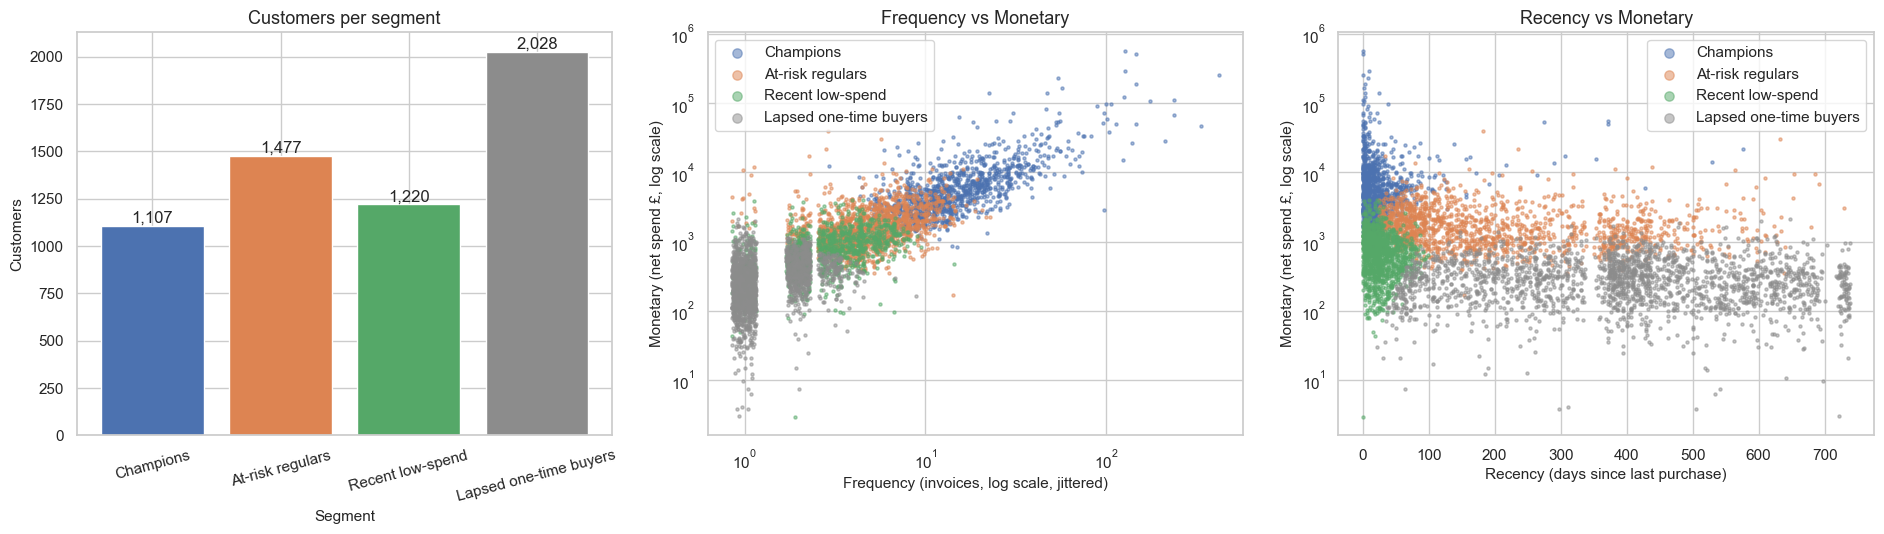

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
sizes = rfm["segment"].value_counts().reindex(SEGMENT_ORDER)
axes[0].bar(sizes.index, sizes.values, color=[SEGMENT_COLORS[s] for s in SEGMENT_ORDER])
for i, count in enumerate(sizes.values):
    axes[0].text(i, count, f"{count:,}", ha="center", va="bottom")
axes[0].set_title("Customers per segment")
axes[0].set_xlabel("Segment")
axes[0].set_ylabel("Customers")
axes[0].tick_params(axis="x", rotation=15)

jitter = np.random.default_rng(RANDOM_STATE).uniform(0.85, 1.15, len(rfm))  # multiplicative jitter for integer Frequency on a log axis
for segment in SEGMENT_ORDER:
    members = rfm["segment"] == segment
    axes[1].scatter(rfm.loc[members, "Frequency"] * jitter[members], rfm.loc[members, "Monetary"], s=5, alpha=0.5,
                    color=SEGMENT_COLORS[segment], label=segment)
    axes[2].scatter(rfm.loc[members, "Recency"], rfm.loc[members, "Monetary"], s=5, alpha=0.5,
                    color=SEGMENT_COLORS[segment], label=segment)
axes[1].set_xscale("log")
axes[1].set_title("Frequency vs Monetary")
axes[1].set_xlabel("Frequency (invoices, log scale, jittered)")
axes[2].set_title("Recency vs Monetary")
axes[2].set_xlabel("Recency (days since last purchase)")
for ax in axes[1:]:
    ax.set_yscale("log")
    ax.set_ylabel("Monetary (net spend £, log scale)")
    ax.legend(markerscale=3)
save_fig("segments")
plt.show()

**Interpretation (from the profile table):**

| Segment | Customers | Evidence (medians) | Plain-language description |
|---|---|---|---|
| **Champions** | 1,107 (19 %) | 13 invoices, £5,032 spent, last purchase 15 days ago, customers for ~22 months | Frequent, recent, high-spending — largely regular wholesale buyers. |
| **At-risk regulars** | 1,477 (25 %) | 5 invoices, £1,530, but last purchase 158 days ago | Good past customers who have not bought for over 5 months. |
| **Recent low-spend** | 1,220 (21 %) | 3 invoices, £702, last purchase 23 days ago, customers for only ~7 months | Active but newer, smaller customers — potential to grow. |
| **Lapsed one-time buyers** | 2,028 (35 %) | 1 invoice, £281, last purchase ~400 days ago | Bought once over a year ago and never returned. |

The scatter plots confirm the structure: Champions sit at the top-right of the Frequency–Monetary plot and the left of
the Recency plot; Recency is what separates At-risk regulars and Lapsed buyers from the active segments. Boundaries
between neighbouring segments are soft (silhouette 0.365).

## Step 6 — Historical value by segment (not CLV)

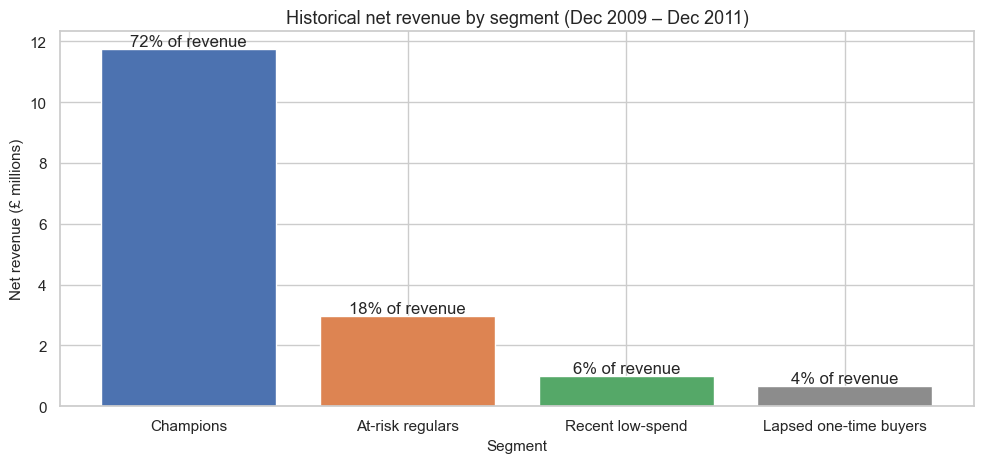

,customers,total_historical_revenue,mean_historical_value,median_historical_value,share_of_customers,share_of_revenue
segment,,,,,,
Champions,1107,11740697.61,10605.870,5032.22,0.190,0.718
At-risk regulars,1477,2957364.53,2002.278,1529.82,0.253,0.181
Recent low-spend,1220,992200.42,813.279,702.18,0.209,0.061
Lapsed one-time buyers,2028,671285.72,331.009,280.82,0.348,0.041


In [9]:
segment_value = rfm.groupby("segment").agg(
    customers=("Monetary", "size"), total_historical_revenue=("Monetary", "sum"),
    mean_historical_value=("Monetary", "mean"), median_historical_value=("Monetary", "median")).reindex(SEGMENT_ORDER)
segment_value["share_of_customers"] = segment_value["customers"] / segment_value["customers"].sum()
segment_value["share_of_revenue"] = segment_value["total_historical_revenue"] / segment_value["total_historical_revenue"].sum()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(segment_value.index, segment_value["total_historical_revenue"] / 1e6, color=[SEGMENT_COLORS[s] for s in SEGMENT_ORDER])
for i, share in enumerate(segment_value["share_of_revenue"]):
    ax.text(i, segment_value["total_historical_revenue"].iloc[i] / 1e6, f"{share:.0%} of revenue", ha="center", va="bottom")
ax.set_title("Historical net revenue by segment (Dec 2009 – Dec 2011)")
ax.set_xlabel("Segment")
ax.set_ylabel("Net revenue (£ millions)")
save_fig("segment_revenue")
plt.show()
segment_value.round(3)

**Interpretation:** **Champions are 19 % of customers but generated 72 % of historical net revenue** (≈ £11.7m).
At-risk regulars add 18 %, so these two segments together account for 90 %. Lapsed one-time buyers are the largest group
(35 % of customers) but contributed only 4 %.

**Business use:** protect Champions (service, account management); run win-back campaigns for At-risk regulars;
nurture Recent low-spend customers so they become regulars; spend little on Lapsed one-time buyers.

These figures are **historical** value. Part 2 tests whether *future* value can be predicted.

# Part 2 — Predicting future customer value (time-split extension)

**Design (prevents leakage):**
- **Calibration window:** 2009-12-01 to 2011-06-09 (18 months). Customer features (RFM, tenure, average order value)
  are computed **only** from this window.
- **Holdout window:** 2011-06-10 to 2011-12-09 (6 months). **Target** = each customer's net spend in this window
  (0 if they did not return; negative net values clipped to 0).
- Customers are randomly split 70/30 into train/test **customers**; because features and target come from different
  time windows, no future information enters the features.

**Models:** a business **baseline** (the customer's calibration spending rate per month × 6), Linear Regression,
Random Forest and XGBoost. The ML models predict `log1p(spend)` (the target is extremely skewed) and are converted back.

**Metrics:** MAE (£ error per customer), **Spearman rank correlation** (does the model *order* customers correctly?),
and **top-20 % capture** (share of next-6-month revenue that comes from the 20 % of customers the model ranks highest —
the practical question for targeting a marketing budget).

In [10]:
CUTOFF = pd.Timestamp("2011-06-10")
calibration = build_rfm(customers_lines, CUTOFF)
holdout_spend = customers_lines[customers_lines["InvoiceDate"] >= CUTOFF].groupby("Customer ID")["revenue"].sum()
calibration["future_spend_6m"] = holdout_spend.reindex(calibration.index).fillna(0).clip(lower=0)
VALUE_FEATURES = ["Recency", "Frequency", "Monetary", "Tenure", "avg_order_value"]

print(f"Customers active in calibration window: {len(calibration):,}")
print(f"Returned and spent in the next 6 months: {(calibration['future_spend_6m'] > 0).mean():.1%}")
print(f"Future spend: mean £{calibration['future_spend_6m'].mean():,.0f}, median £{calibration['future_spend_6m'].median():,.0f}")

value_train, value_test = train_test_split(calibration, test_size=0.3, random_state=RANDOM_STATE)
y_value_test = value_test["future_spend_6m"]

value_predictions = {"Baseline (past monthly rate × 6)":
                     value_test["Monetary"] / (value_test["Tenure"].clip(lower=30) / 30) * 6}
value_models = {
    "Linear Regression": make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=5, random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=RANDOM_STATE),
}
for name, template in value_models.items():
    model = clone(template).fit(value_train[VALUE_FEATURES], np.log1p(value_train["future_spend_6m"]))
    value_predictions[name] = np.clip(np.expm1(model.predict(value_test[VALUE_FEATURES])), 0, None)
    value_models[name] = model

def top_share_captured(actual, predicted, share=0.2):
    top = pd.Series(np.asarray(predicted), index=actual.index).nlargest(int(len(actual) * share)).index
    return actual.loc[top].sum() / actual.sum()

value_metrics = pd.DataFrame({
    name: {"MAE": mean_absolute_error(y_value_test, p), "Spearman": spearmanr(y_value_test, p)[0],
           "top20_capture": top_share_captured(y_value_test, p),
           "RMSE": np.sqrt(mean_squared_error(y_value_test, p)), "MedAE": median_absolute_error(y_value_test, p),
           "R2": r2_score(y_value_test, p), "R2_log": r2_score(np.log1p(y_value_test), np.log1p(p))}
    for name, p in value_predictions.items()}).T.sort_values("Spearman", ascending=False)
print(f"Perfect-knowledge top-20 % capture (upper bound): {top_share_captured(y_value_test, y_value_test):.1%}")
value_metrics.round(3)

Customers active in calibration window: 4,929
Returned and spent in the next 6 months: 52.0%
Future spend: mean £859, median £91


Perfect-knowledge top-20 % capture (upper bound): 88.3%


,MAE,Spearman,top20_capture,RMSE,MedAE,R2,R2_log
XGBoost,751.770,0.640,0.782,4967.528,93.616,0.427,0.402
Random Forest,704.792,0.625,0.772,4699.232,95.499,0.487,0.382
Linear Regression,943.333,0.607,0.757,6977.962,97.759,-0.131,0.361
Baseline (past monthly rate × 6),732.458,0.597,0.786,2488.932,308.863,0.856,-0.401


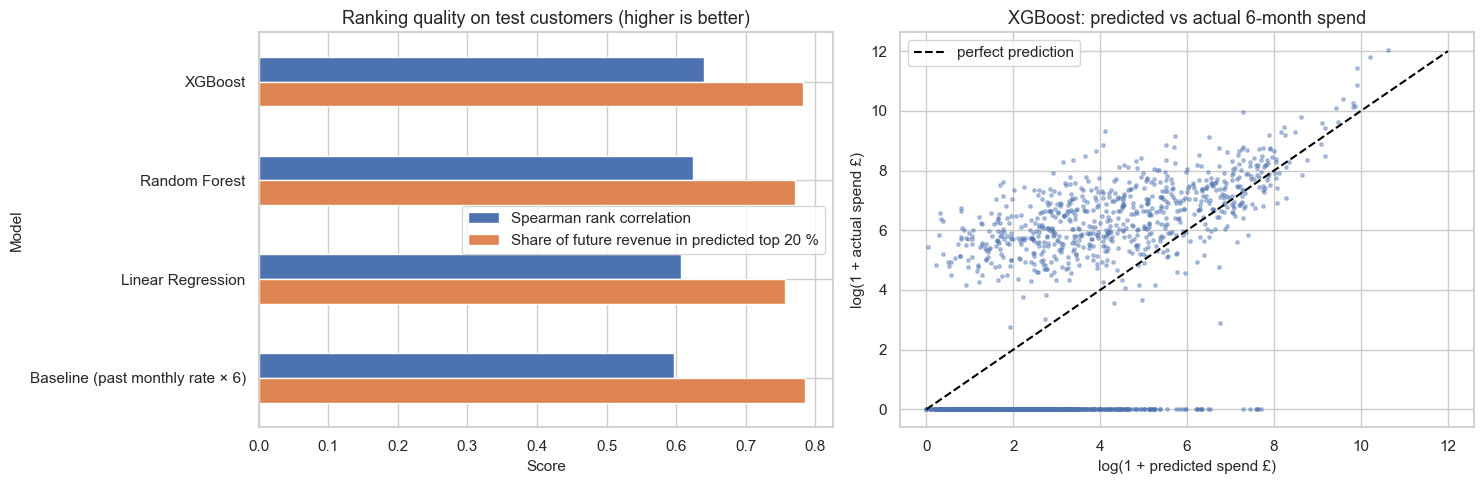

In [11]:
best_value_model = value_metrics.drop("Baseline (past monthly rate × 6)")["Spearman"].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
value_metrics[["Spearman", "top20_capture"]].plot.barh(ax=axes[0], color=[MAIN_COLOR, ACCENT_COLOR])
axes[0].invert_yaxis()
axes[0].set_title("Ranking quality on test customers (higher is better)")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Model")
axes[0].legend(["Spearman rank correlation", "Share of future revenue in predicted top 20 %"])
axes[1].scatter(np.log1p(value_predictions[best_value_model]), np.log1p(y_value_test), s=6, alpha=0.4, color=MAIN_COLOR)
axes[1].plot([0, 12], [0, 12], color="black", linestyle="--", label="perfect prediction")
axes[1].set_title(f"{best_value_model}: predicted vs actual 6-month spend")
axes[1].set_xlabel("log(1 + predicted spend £)")
axes[1].set_ylabel("log(1 + actual spend £)")
axes[1].legend()
save_fig("future_value_models")
plt.show()

**Additional regression metrics (RMSE, MedAE, R² on £ and on log scale):**
- The **baseline** has the best raw-£ R² (0.86) and RMSE (£2,489). Raw-£ errors are dominated by a few very large
  wholesale customers, and the baseline extrapolates their spending directly.
- The same baseline is **worst for typical customers**: median error £309 vs ≈ £94 for the ML models, and **R² on the
  log scale −0.40** (worse than predicting the average). It cannot predict that many customers will spend £0.
- **XGBoost** has the best log-scale R² (0.40) and Spearman (0.64); **Random Forest** has the best MAE (£705).
  Linear Regression has a negative raw R² (−0.13) because it over-predicts large customers.
- In short: use the baseline to estimate *how much the biggest accounts will spend*, and the tree models to *rank and
  size typical customers*.

**Interpretation:**
- Future spend is very hard to predict per customer: only **52 %** of customers returned in the next 6 months, and the
  median future spend is £91 against a mean of £859 — a few large buyers dominate.
- **Ranking:** XGBoost has the best rank correlation (Spearman 0.64 vs 0.60 for the baseline), but for the practical
  targeting question all approaches are equal: each puts about **77–79 % of next-6-month revenue** into its predicted
  top 20 % of customers (the baseline is marginally best at 78.6 %; the perfect-knowledge upper bound is 88 %).
- **Exact amounts:** Random Forest has the lowest MAE (≈ £705 vs ≈ £732 for the baseline), a small gain. The log-scale
  Linear Regression over-predicts large customers (MAE ≈ £943).
- **Conclusion:** past spending already tells us most of what we can know. ML gives small, inconsistent improvements
  (better overall ranking and MAE, but not better top-20 % targeting). This is a genuine, measured CLV result
  on a proper time split, but over a short 6-month horizon, so it is **not** full lifetime value.

## Step 7 — Save outputs

In [12]:
customer_table = rfm.reset_index()[["Customer ID", "Recency", "Frequency", "Monetary", "avg_order_value", "Tenure", "cluster", "segment"]]
customer_table.round(2).to_csv(PRED_DIR / "03_customer_segments.csv", index=False)
cluster_profile.round(3).to_csv(TABLE_DIR / "03_cluster_profiles.csv")
segment_value.round(4).to_csv(TABLE_DIR / "03_segment_value.csv")
k_evaluation.assign(selected=lambda d: d.index == N_CLUSTERS).round(4).to_csv(TABLE_DIR / "03_k_evaluation.csv")
value_metrics.round(4).to_csv(TABLE_DIR / "03_future_value_metrics.csv", index_label="model")
joblib.dump({"pipeline": segmentation_pipeline, "rfm_columns": RFM_COLUMNS, "segment_names": segment_names,
             "snapshot_date": str(SNAPSHOT_DATE.date()), "silhouette": final_silhouette},
            MODEL_DIR / "03_segmentation_pipeline.joblib")
print("Saved customer segments, profiles, evaluation tables and the segmentation pipeline.")

Saved customer segments, profiles, evaluation tables and the segmentation pipeline.


## Conclusion and limitations

- **Segmentation:** RFM (log-transformed, standardised) + K-Means with **K = 4** gives four clearly
  interpretable segments: Champions (19 % of customers, 72 % of revenue), At-risk regulars (25 %, 18 %),
  Recent low-spend (21 %, 6 %) and Lapsed one-time buyers (35 %, 4 %). (Silhouette 0.365.)
- **Future value:** with features from the first 18 months, XGBoost ranks customers' next-6-month spend slightly better
  than a past-spending baseline (Spearman 0.64 vs 0.60) and Random Forest has a slightly lower MAE, but for top-20 %
  targeting the simple baseline is just as good (≈ 79 % of future revenue captured).
- **Snapshot / window:** segments are measured at 2011-12-10 over two years; recently acquired customers have had less
  time to build Frequency and Monetary.
- **Limitations:** 22 % of transaction lines have no Customer ID and are excluded; wholesalers and retail customers are
  mixed; the future-value horizon is only 6 months and includes the autumn peak, so it is seasonal.
- **What would improve it:** customer type (wholesale vs retail), marketing contact history, and more years of data for a true multi-year CLV.